# 01 - Veri Keşfi (EDA)
**Proje:** Havayolu Yolcularının Memnuniyet Düzeylerinin Tahmin Edilmesi (U08)

Bu defterde veri seti tanıtılır, veri kalitesi incelenir ve memnuniyetle ilişkili
örüntüler görselleştirilir. Modelleme kararlarının gerekçeleri buradan çıkar.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

from src import data_loader
from src import visualization as viz
from src.preprocessing import AirlinePreprocessor, split_xy

viz.set_style()
pd.set_option("display.max_columns", 30)

## 1. Veri setini yükleme
Kaggle'ın hazır train/test bölünmesi kullanılır. Test seti modelleme boyunca **kapalı** tutulur.

In [2]:
train, test = data_loader.load_data()
full = pd.concat([train, test], ignore_index=True)
print(data_loader.summary(train, test))
full.head()

{'train_satir': 103904, 'test_satir': 25976, 'toplam': 129880, 'ozellik_sayisi': 22, 'tekrar_eden_satir': 0, 'eksik_arrival_delay': 393, 'memnun_orani': np.float64(0.4345), 'dep_arr_korelasyon': np.float64(0.9653)}


,gender,customer_type,age,type_of_travel,travel_class,flight_distance,inflight_wifi,time_convenience,online_booking,gate_location,food_drink,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay,arrival_delay,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


## 2. Veri kalitesi
Eksik değerler, benzersiz değer sayıları ve hizmet puanlarındaki `0` değerleri (*uygulanamaz / puanlanmamış*).

In [3]:
data_loader.quality_report(full)

,tip,eksik,eksik_%,benzersiz,sifir_puan
gender,object,0,0.0,2,NaN
customer_type,object,0,0.0,2,NaN
age,int64,0,0.0,75,NaN
type_of_travel,object,0,0.0,2,NaN
travel_class,object,0,0.0,3,NaN
flight_distance,int64,0,0.0,3821,NaN
inflight_wifi,int64,0,0.0,6,3916.0
time_convenience,int64,0,0.0,6,6681.0
online_booking,int64,0,0.0,6,5682.0
gate_location,int64,0,0.0,6,1.0


In [4]:
full.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,129880.0,39.43,15.12,7.0,27.0,40.0,51.0,85.0
flight_distance,129880.0,1190.32,997.45,31.0,414.0,844.0,1744.0,4983.0
inflight_wifi,129880.0,2.73,1.33,0.0,2.0,3.0,4.0,5.0
time_convenience,129880.0,3.06,1.53,0.0,2.0,3.0,4.0,5.0
online_booking,129880.0,2.76,1.40,0.0,2.0,3.0,4.0,5.0
gate_location,129880.0,2.98,1.28,0.0,2.0,3.0,4.0,5.0
food_drink,129880.0,3.20,1.33,0.0,2.0,3.0,4.0,5.0
online_boarding,129880.0,3.25,1.35,0.0,2.0,3.0,4.0,5.0
seat_comfort,129880.0,3.44,1.32,0.0,2.0,4.0,5.0,5.0
inflight_entertainment,129880.0,3.36,1.33,0.0,2.0,4.0,4.0,5.0


## 3. Hedef değişken
Sınıflar dengeye yakın (%56,6 nötr/memnun değil, %43,4 memnun). Accuracy tek başına yanıltıcı olmaz; yine de F1 ve ROC-AUC da raporlanır.

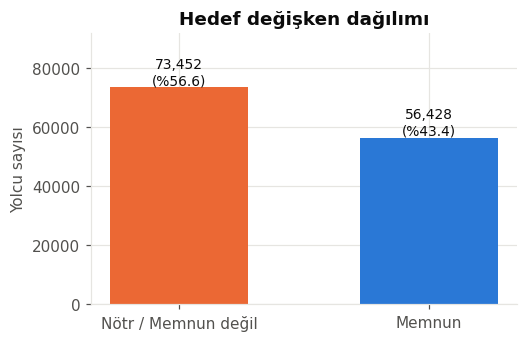

In [5]:
X_full, y_full = split_xy(full)
viz.plot_target(y_full)
plt.show()

## 4. Segment analizi
Kabin sınıfı, seyahat amacı ve müşteri sadakati memnuniyeti güçlü biçimde ayrıştırıyor.

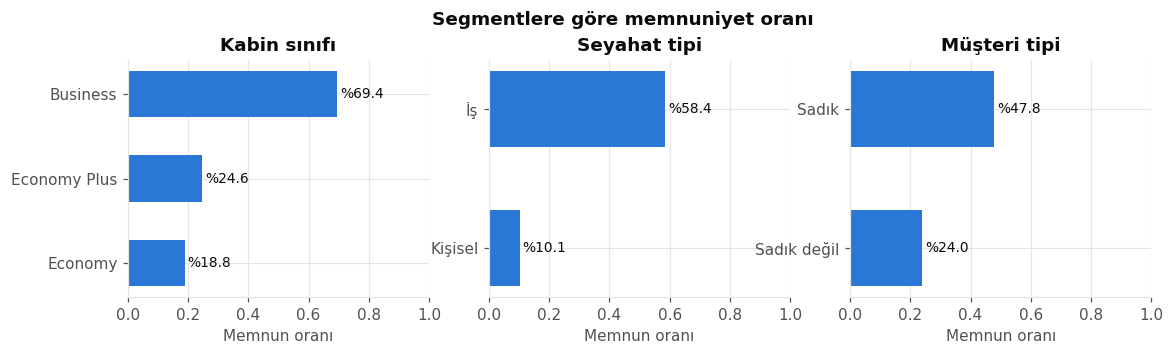

In [6]:
viz.plot_segments(X_full, y_full)
plt.show()

## 5. Hizmet puanları
Memnun ve memnun olmayan yolcuların ortalama puanları arasındaki fark, hangi hizmetin ayırt edici olduğunu gösterir.

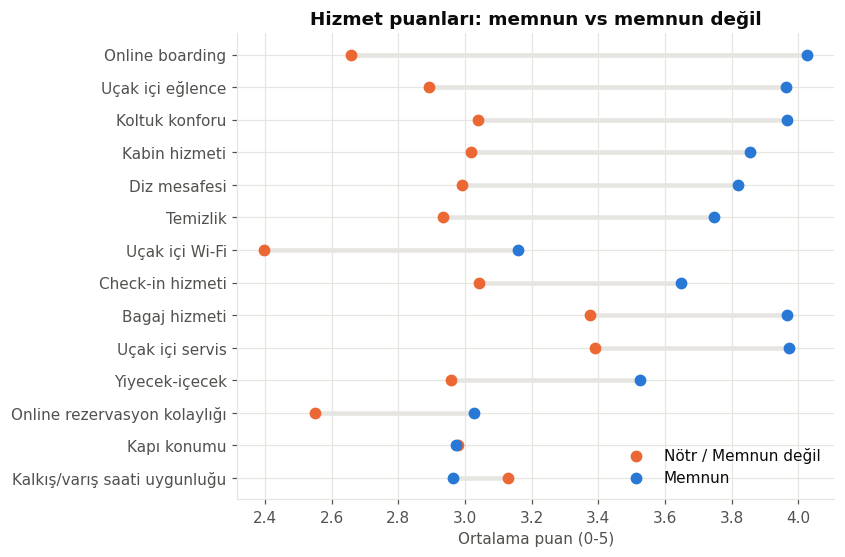

In [7]:
viz.plot_service_means(X_full, y_full)
plt.show()

## 6. Korelasyon
Kodlanmış tüm özellikler ve hedef arasındaki Pearson korelasyonları.

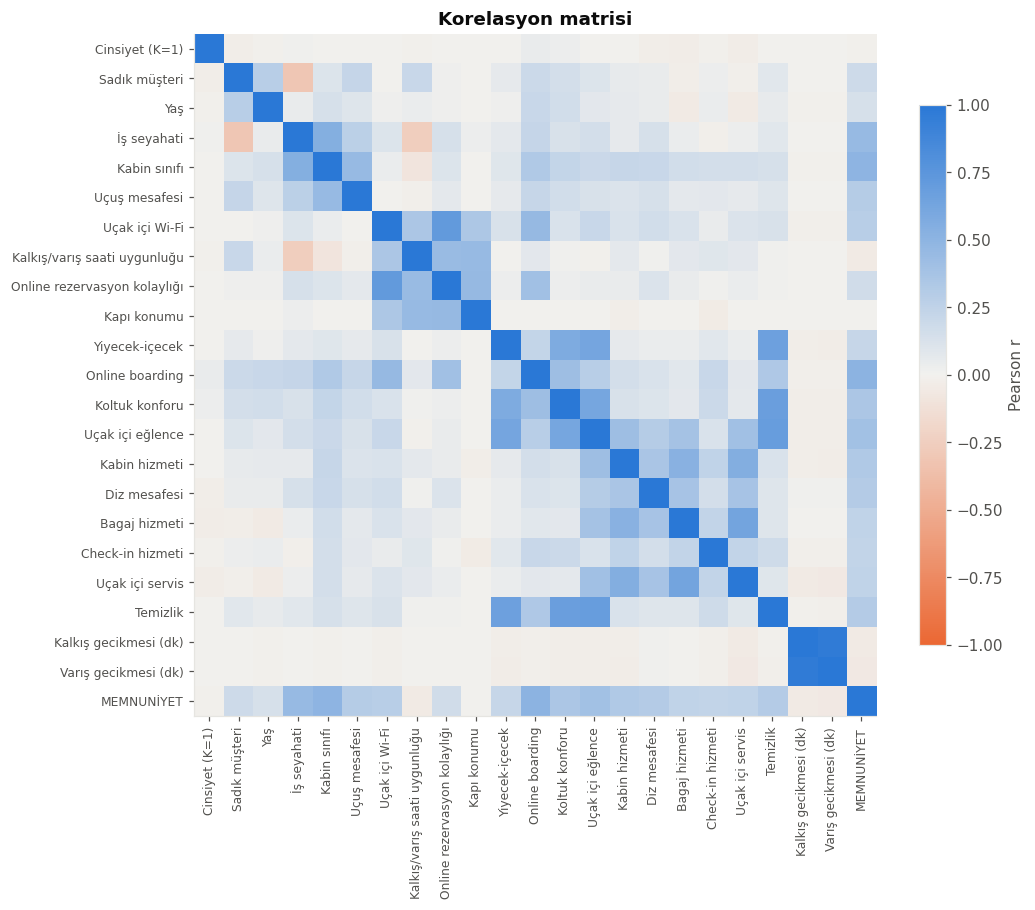

online_boarding           0.502
travel_class              0.493
type_of_travel            0.450
inflight_entertainment    0.398
seat_comfort              0.349
onboard_service           0.322
leg_room                  0.312
cleanliness               0.307
flight_distance           0.298
inflight_wifi             0.283
baggage_handling          0.249
inflight_service          0.245
checkin_service           0.237
food_drink                0.211
customer_type             0.186
online_booking            0.169
age                       0.134
gate_location            -0.003
gender                   -0.011
departure_delay          -0.051
time_convenience         -0.054
arrival_delay            -0.058
Name: target, dtype: float64

In [8]:
num = AirlinePreprocessor().fit_transform(X_full).assign(target=y_full.values)
viz.plot_correlation(num)
plt.show()
num.corr()["target"].drop("target").sort_values(ascending=False).round(3)

## 7. Gecikmeler
Kalkış ve varış gecikmesi çok yüksek korelasyonlu (r = 0,965). Bu yüzden eksik `arrival_delay` değerleri aynı uçuşun `departure_delay` değeri ile doldurulur.

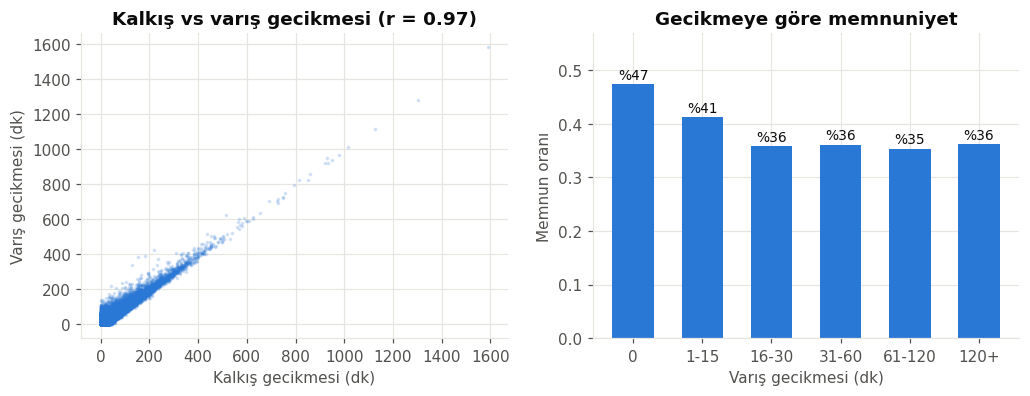

In [9]:
viz.plot_delays(X_full, y_full)
plt.show()

## 8. '0' puanlar
Bazı hizmetlerde 0 değeri bulunuyor; bu ölçekte 0 = *uygulanamaz*. Ağaç tabanlı modeller 0'ı ayrı bir dalda yakalayabildiği için ayrı bir değer olarak korunur.

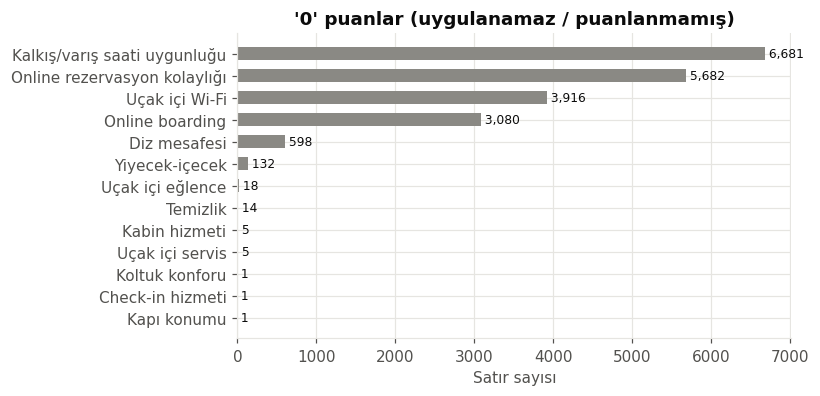

In [10]:
viz.plot_zero_ratings(X_full)
plt.show()

## Yorum
- Veri temiz: 129.880 satırda tekrar eden satır yok; yalnızca `arrival_delay` sütununda 393 eksik
  değer (%0,3) var.
- Hedef dengeye yakın: %56,6 nötr/memnun değil, %43,4 memnun.
- Segmentler belirgin biçimde ayrışıyor. Memnun oranı Business'ta %69,4, Economy'de %18,8;
  iş seyahatinde %58,4, kişisel seyahatte %10,1; sadık müşterilerde %47,8, sadık olmayanlarda
  %24,0. Cinsiyete göre belirgin bir fark yok (kadın %42,9, erkek %44,0).
- Memnun ve memnun olmayan yolcular arasındaki ortalama puan farkı en çok online boarding'de
  (1,37), uçak içi eğlencede (1,07) ve koltuk konforunda (0,93). Kapı konumu ve kalkış/varış saati
  uygunluğu ayırt edici değil.
- Hedefle en yüksek korelasyon online boarding (r = 0,50), kabin sınıfı (0,49) ve seyahat tipinde
  (0,45).
- Kalkış ve varış gecikmesi arasında r = 0,965. Memnun oranı gecikmesiz uçuşlarda %47,4, 16 dk ve
  üzeri gecikmelerde %35,3–36,2; gecikmelerin hedefle korelasyonu zayıf
  (kalkış r = −0,05, varış r = −0,06).
- '0' puanlar en çok kalkış/varış saati uygunluğu (6.681), online rezervasyon (5.682) ve Wi-Fi'de
  (3.916) görülüyor.